# EDA – EEG ADHD vs Control

Tylko eksploracja. Cech **nie wybieramy** na podstawie tych wykresów (EDA obejmuje cały zbiór, także przyszły test) – pasma i theta/beta bierzemy z literatury.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import welch
from src.data import load_raw, channel_names, FS

RESULTS = ROOT / "results"
df = load_raw()
ch = channel_names(df)
df.shape, len(ch)

((2166383, 21), 19)

## 1. Sprawdzenie pliku: braki, klasy, liczba osób

In [2]:
print("NaN:", int(df.isna().sum().sum()))
print("Wiersze w klasach:", df["Class"].value_counts().to_dict())
print("Osoby w klasach:", df.groupby("Class")["ID"].nunique().to_dict())
print("ID z więcej niż jedną klasą:", int((df.groupby("ID")["Class"].nunique() > 1).sum()))

NaN: 0


Wiersze w klasach: {'ADHD': 1207069, 'Control': 959314}


Osoby w klasach: {'ADHD': 61, 'Control': 60}


ID z więcej niż jedną klasą: 0


## 2. Czy wiersze osoby tworzą jeden ciągły blok?

Brak kolumny czasu – zakładamy, że kolejność wierszy = kolejność próbek. Jeśli liczba bloków = liczba osób, każda osoba to jeden nieprzerwany fragment.

In [3]:
blocks = (df["ID"] != df["ID"].shift()).sum()
print("Bloki:", int(blocks), "| osoby:", df["ID"].nunique())

Bloki: 121 | osoby: 121


## 3. Długość nagrań

Długość zależała od tempa dziecka w zadaniu – sprawdzamy, czy różni się między klasami.

         count   mean   std   min    25%    50%    75%    max
cls                                                          
ADHD      61.0  154.6  58.1  72.5  111.8  143.7  185.0  337.9
Control   60.0  124.9  29.9  62.4  104.6  122.1  139.1  203.0


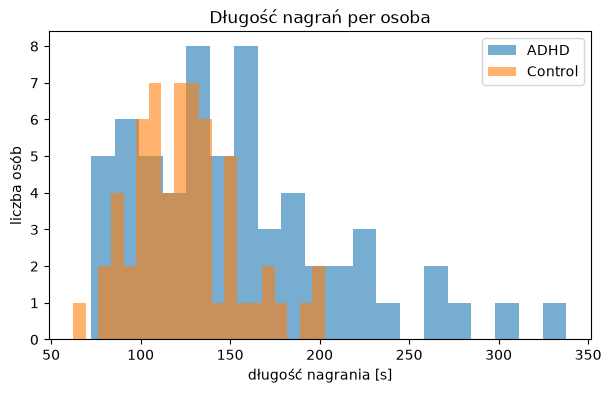

In [4]:
lens = df.groupby("ID", sort=False).agg(n=("ID", "size"), cls=("Class", "first"))
lens["sec"] = lens["n"] / FS
print(lens.groupby("cls")["sec"].describe().round(1))

fig, ax = plt.subplots(figsize=(7, 4))
for cls in ["ADHD", "Control"]:
    ax.hist(lens.loc[lens.cls == cls, "sec"], bins=20, alpha=0.6, label=cls)
ax.set(xlabel="długość nagrania [s]", ylabel="liczba osób", title="Długość nagrań per osoba")
ax.legend()
fig.savefig(RESULTS / "eda_lengths.png", dpi=120, bbox_inches="tight")

## 4. Amplitudy i artefakty

In [5]:
print(df[ch].describe().T[["mean", "std", "min", "max"]].round(0))
share = (df[ch].abs() > 1000).groupby(df["Class"]).mean().mean(axis=1)
print("\nOdsetek próbek z |x| > 1000:", share.round(4).to_dict())

      mean    std      min      max
Fp1  136.0  276.0  -3786.0  13813.0
Fp2  136.0  276.0 -13224.0   4802.0
F3   142.0  221.0  -3921.0   5020.0
F4   136.0  213.0 -13237.0   4802.0
C3   142.0  223.0  -3921.0   5430.0
C4   142.0  211.0  -3921.0   5020.0
P3   142.0  230.0  -3921.0   5020.0
P4   142.0  210.0  -3958.0   5020.0
O1   142.0  236.0  -3995.0   5020.0
O2   142.0  213.0  -3921.0   5020.0
F7   142.0  243.0  -3995.0   5020.0
F8   142.0  227.0  -3958.0   5020.0
T7   142.0  227.0  -3958.0   5020.0
T8   141.0  227.0  -3995.0   5064.0
P7   142.0  208.0  -3921.0   5016.0
P8   141.0  205.0  -3958.0   5020.0
Fz   135.0  252.0  -3786.0   4802.0
Cz   135.0  213.0  -3751.0   4802.0
Pz   135.0  227.0  -3751.0   4802.0



Odsetek próbek z |x| > 1000: {'ADHD': 0.0047, 'Control': 0.0107}


## 5. Podgląd surowego sygnału (5 s)

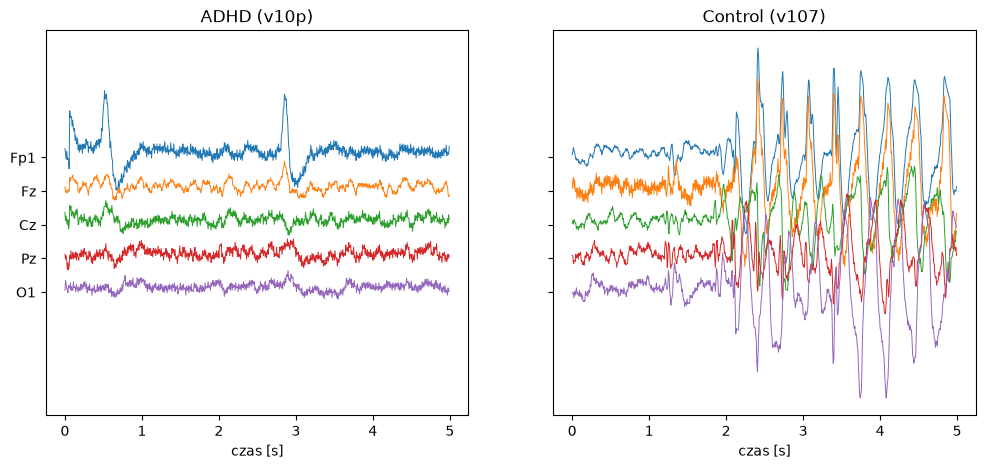

In [6]:
ids = {cls: lens.index[lens.cls == cls][0] for cls in ["ADHD", "Control"]}
show = ["Fp1", "Fz", "Cz", "Pz", "O1"]
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, (cls, pid) in zip(axes, ids.items()):
    seg = df.loc[df.ID == pid, show].iloc[: 5 * FS].to_numpy()
    t = np.arange(len(seg)) / FS
    for i, name in enumerate(show):
        ax.plot(t, seg[:, i] - i * 1000, lw=0.7)
    ax.set_yticks([-i * 1000 for i in range(len(show))], show)
    ax.set(title=f"{cls} ({pid})", xlabel="czas [s]")
fig.savefig(RESULTS / "eda_raw.png", dpi=120, bbox_inches="tight")

## 6. Widmo mocy (Welch)

Najpierw widmo **każdej osoby** (średnia z kanałów), potem średnia osób w klasie – żeby długie nagrania nie miały większej wagi. `nperseg=256` = okno 2 s → rozdzielczość 0.5 Hz.

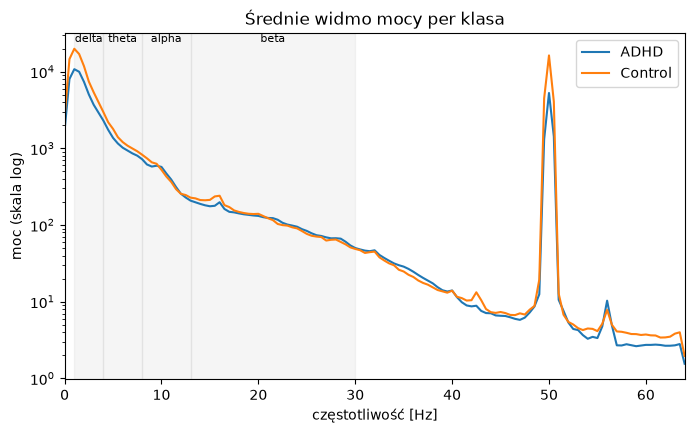

In [7]:
BANDS = {"delta": (1, 4), "theta": (4, 8), "alpha": (8, 13), "beta": (13, 30)}

psd_rows = []
for pid, g in df.groupby("ID", sort=False):
    f, p = welch(g[ch].to_numpy(), fs=FS, nperseg=2 * FS, axis=0)  # p: (częstotliwości, kanały)
    psd_rows.append({"ID": pid, "cls": g["Class"].iat[0], "psd": p})

fig, ax = plt.subplots(figsize=(8, 4.5))
for cls in ["ADHD", "Control"]:
    mean_psd = np.mean([r["psd"].mean(axis=1) for r in psd_rows if r["cls"] == cls], axis=0)
    ax.semilogy(f, mean_psd, label=cls)
for name, (lo, hi) in BANDS.items():
    ax.axvspan(lo, hi, alpha=0.08, color="gray")
    ax.text((lo + hi) / 2, ax.get_ylim()[1], name, ha="center", va="top", fontsize=8)
ax.set(xlabel="częstotliwość [Hz]", ylabel="moc (skala log)", title="Średnie widmo mocy per klasa", xlim=(0, FS / 2))
ax.legend()
fig.savefig(RESULTS / "eda_psd.png", dpi=120, bbox_inches="tight")

## 7. Stosunek theta/beta per osoba (Cz)

Klasyczny, ale sporny marker ADHD; historycznie mierzony głównie w spoczynku, a tu jest zadanie.

         count  mean   std   min   25%   50%   75%    max
cls                                                      
ADHD      61.0  3.67  1.62  1.18  2.23  3.59  4.74   9.05
Control   60.0  4.21  2.10  0.83  2.79  3.81  5.44  11.15


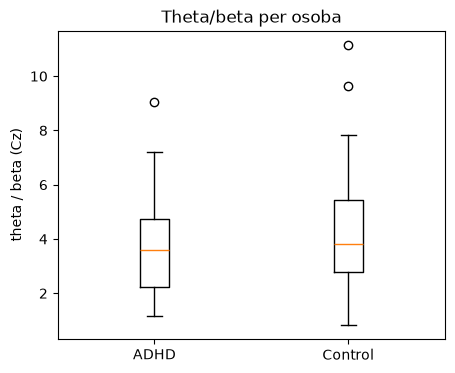

In [8]:
def band_power(f, p, lo, hi):
    return p[(f >= lo) & (f < hi)].sum(axis=0)

cz = ch.index("Cz")
tbr = pd.DataFrame({
    "cls": [r["cls"] for r in psd_rows],
    "tbr": [band_power(f, r["psd"], *BANDS["theta"])[cz] / band_power(f, r["psd"], *BANDS["beta"])[cz] for r in psd_rows],
})
print(tbr.groupby("cls")["tbr"].describe().round(2))

fig, ax = plt.subplots(figsize=(5, 4))
ax.boxplot([tbr.loc[tbr.cls == c, "tbr"] for c in ["ADHD", "Control"]], tick_labels=["ADHD", "Control"])
ax.set(ylabel="theta / beta (Cz)", title="Theta/beta per osoba")
fig.savefig(RESULTS / "eda_theta_beta.png", dpi=120, bbox_inches="tight")